[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-1/blob/main/notebooks/ch04_KidsLab02_MNIST_Digit_Recognition.ipynb)

**The Why Book of Deep Learning, Part 1** by Dr. Philemon Paul Daniel

**Chapter 4: Stacking Neurons: Dense Layers and the MLP** (Part I: The Learning Machine). This lab comes from the simplified video course for kids, kept for comparison.

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-1/read.html?ch=4](https://www.micyaai.com/books/why-deep-learning-1/read.html?ch=4)
* The simplified video course for kids that this book grew from: [aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)

Tested with TensorFlow 2.21 and Keras 3.14. In Colab: *Runtime > Run all*. A GPU runtime makes the bigger
models faster but none of them needs one.

---


# 🔢 Interactive Digit Recognition (0-9)
## Train AI & Upload YOUR Handwritten Digit!

**What you'll do:**
1. Explore MNIST digits interactively
2. Train a neural network
3. Upload your own digit and watch AI recognize it!

---

> ### ✅ Checked edition (November 2026)
> This notebook was re-run top to bottom and checked for *The Why Book of Deep Learning, Part 1*. What changed from the original:
>
> * **Runs outside Colab too.** `from google.colab import files` stopped the notebook in its first code cell anywhere else. The upload now goes through `get_images()`: the upload button in Colab, a `MY_IMAGES` list in Jupyter, or a demo "photo" drawn by the notebook.
> * **Better photo preprocessing** (the same function as Lab 02): Otsu threshold instead of an 11-pixel adaptive threshold (which left thick strokes hollow), all strokes kept, thin lines thickened, MNIST's 20×20-box-and-centre-of-mass recipe. Tested on ten demo digits with a quickly trained copy of this network: 5/10 right before, 9/10 after.
> * `keras.Input(shape=(784,))` replaces the deprecated `input_shape=`; training prints one line per epoch.
> * "Trained on 60,000 images" corrected to 54,000 (`validation_split=0.1` keeps 6,000 back).
> * The two near-identical copies of this notebook in the original download are not repeated in this set: they are the same notebook.

## 📦 Cell 1: Import Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist

np.random.seed(42)
tf.random.set_seed(42)

print("✅ Libraries loaded!")
print(f"TensorFlow: {tf.__version__}")

✅ Libraries loaded!
TensorFlow: 2.21.0


---
## 📊 Cell 2: Load MNIST Dataset

In [2]:
print("📥 Loading MNIST dataset...\n")

(X_train, y_train), (X_test, y_test) = mnist.load_data()

print(f"✅ MNIST loaded!")
print(f"Training images: {X_train.shape[0]:,}")
print(f"Test images: {X_test.shape[0]:,}")
print(f"Image size: {X_train.shape[1]}×{X_train.shape[2]} pixels")
print(f"\nDigits: 0, 1, 2, 3, 4, 5, 6, 7, 8, 9")

📥 Loading MNIST dataset...



✅ MNIST loaded!
Training images: 60,000
Test images: 10,000
Image size: 28×28 pixels

Digits: 0, 1, 2, 3, 4, 5, 6, 7, 8, 9


---
## 🎨 Cell 3: Interactive MNIST Explorer!

**Enter a number (0-59999) to see that specific digit from the training set!**

🎯 Try different numbers to explore the dataset!



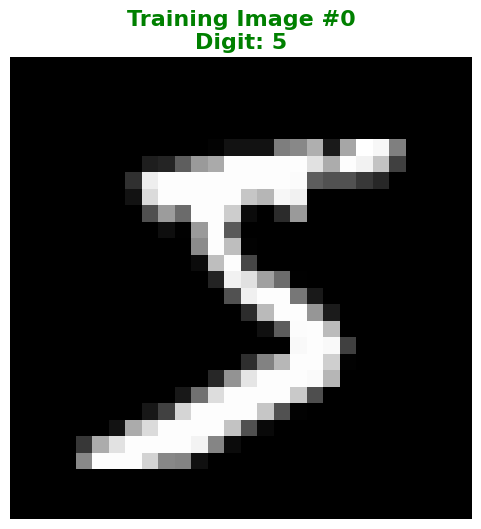


📊 Image #0
Label: 5
Shape: (28, 28)
Pixel range: 0 to 255


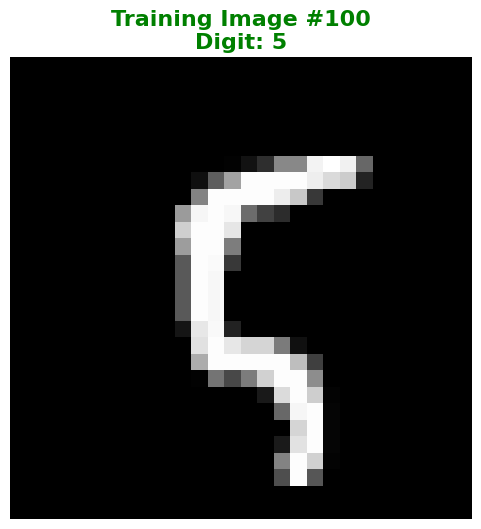


📊 Image #100
Label: 5
Shape: (28, 28)
Pixel range: 0 to 255


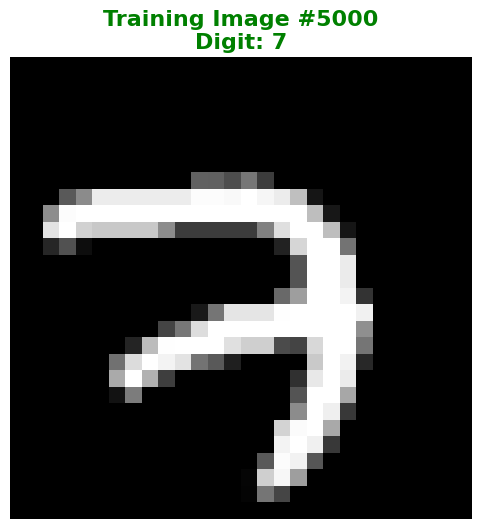


📊 Image #5000
Label: 7
Shape: (28, 28)
Pixel range: 0 to 254


In [3]:
def explore_mnist(index):
    """
    Show a specific MNIST training image by index.
    """
    if index < 0 or index >= len(X_train):
        print(f"❌ Index must be between 0 and {len(X_train)-1}")
        return

    image = X_train[index]
    label = y_train[index]

    plt.figure(figsize=(6, 6))
    plt.imshow(image, cmap='gray')
    plt.title(f'Training Image #{index}\nDigit: {label}',
             fontsize=16, fontweight='bold', color='green')
    plt.axis('off')
    plt.show()

    print(f"\n📊 Image #{index}")
    print(f"Label: {label}")
    print(f"Shape: {image.shape}")
    print(f"Pixel range: {image.min()} to {image.max()}")

# Try it! Change the number to explore different digits
print("🎯 Try different numbers to explore the dataset!\n")
explore_mnist(0)      # Shows image #0
explore_mnist(100)    # Shows image #100
explore_mnist(5000)   # Shows image #5000

---
## 🎲 Cell 4: Random Digit Explorer

**Want to see random digits? Run this cell multiple times!**

🎲 Random pick: Image #56422



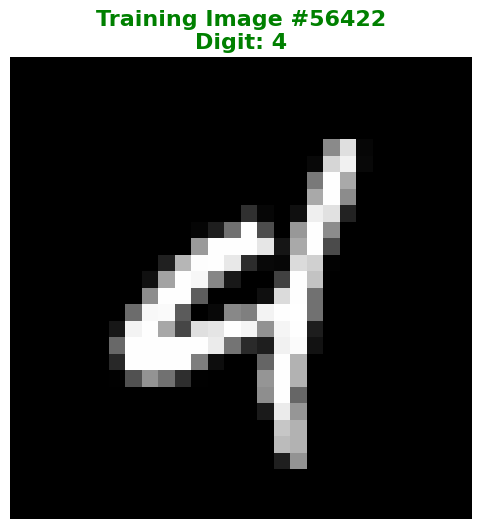


📊 Image #56422
Label: 4
Shape: (28, 28)
Pixel range: 0 to 255

💡 Run this cell again to see another random digit!


In [4]:
# Pick a random index
random_index = np.random.randint(0, len(X_train))

print(f"🎲 Random pick: Image #{random_index}\n")
explore_mnist(random_index)

print("\n💡 Run this cell again to see another random digit!")

---
## 🎨 Cell 5: Show Examples of Each Digit

See what each digit (0-9) looks like with different handwriting styles!

🎨 Showing 5 examples of each digit (0-9)...



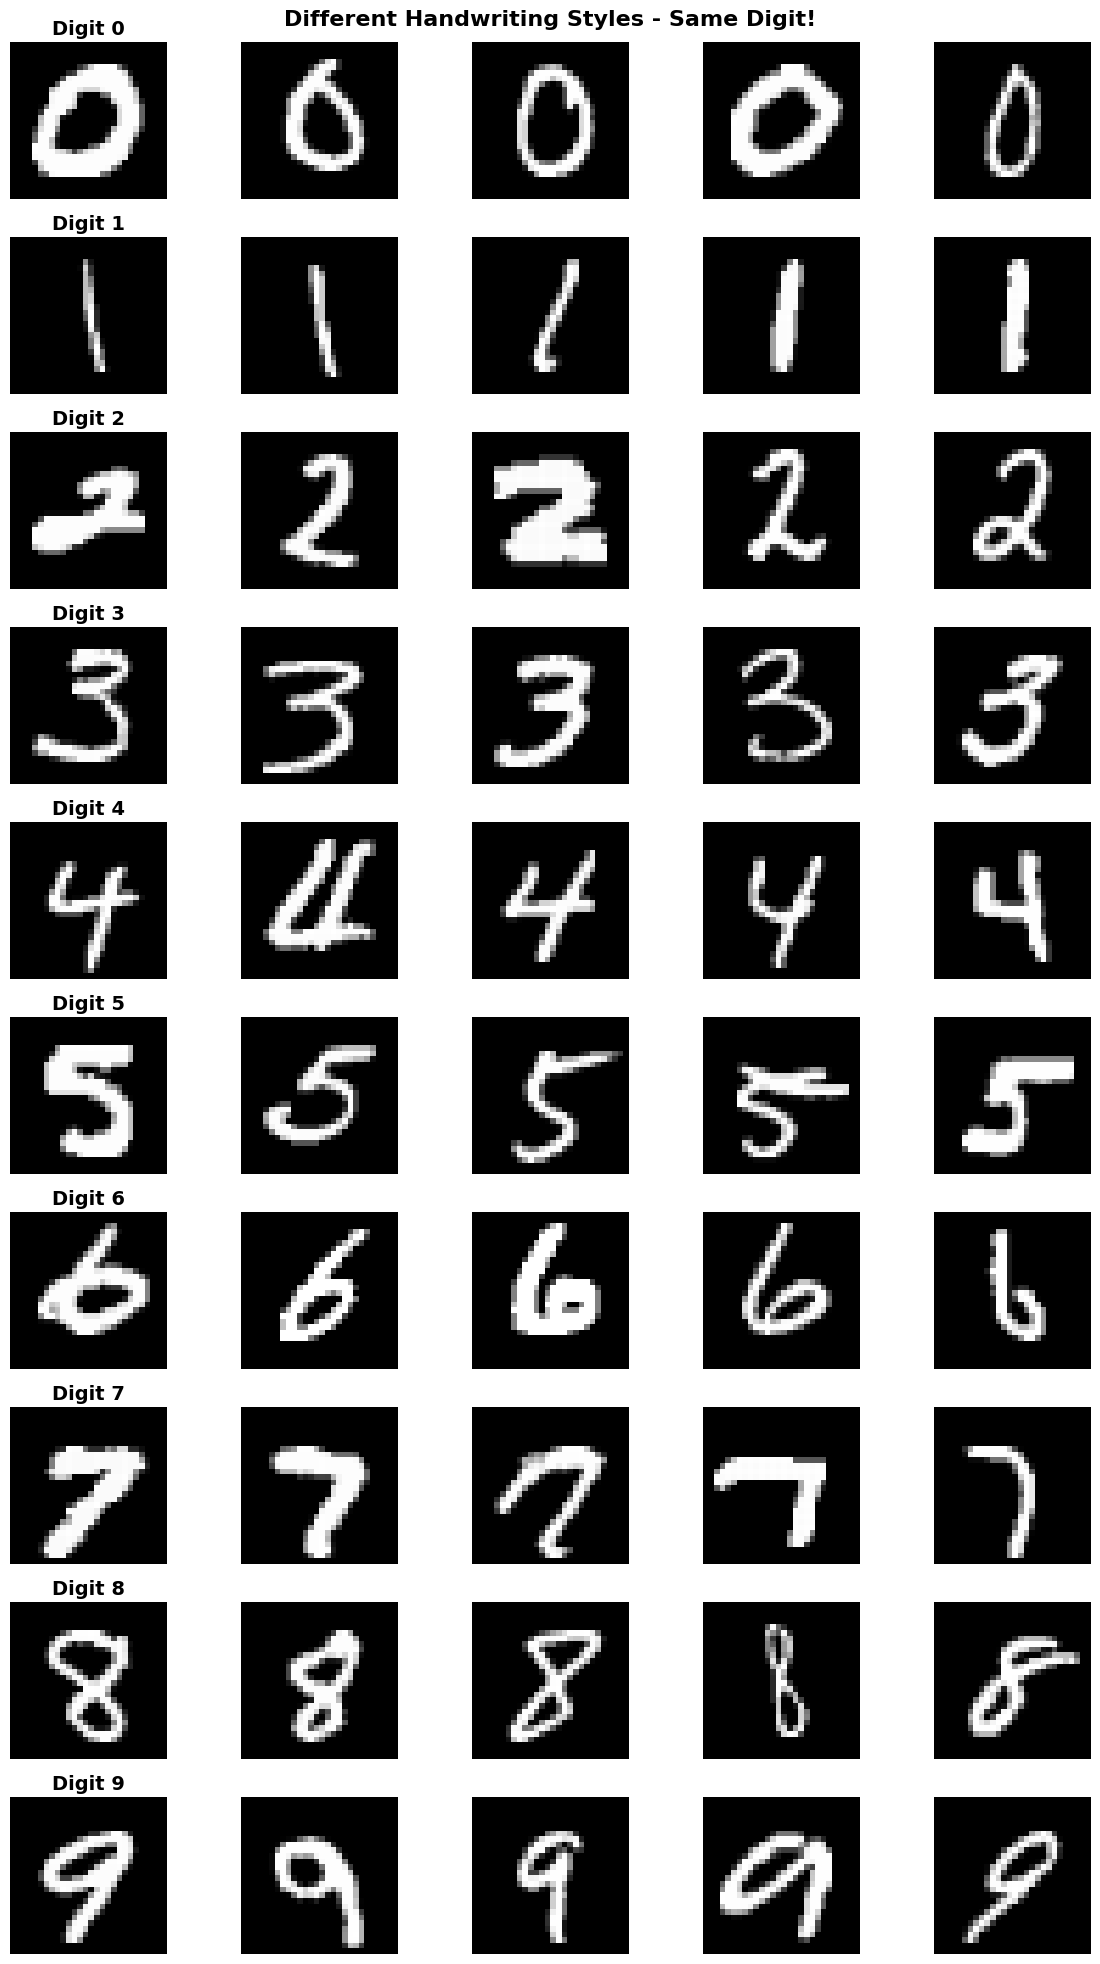

✅ Notice how different people write the same digit differently!


In [5]:
print("🎨 Showing 5 examples of each digit (0-9)...\n")

fig, axes = plt.subplots(10, 5, figsize=(12, 20))

for digit in range(10):
    # Find all examples of this digit
    digit_indices = np.where(y_train == digit)[0]
    # Pick 5 random ones
    samples = np.random.choice(digit_indices, 5, replace=False)

    for i, idx in enumerate(samples):
        axes[digit, i].imshow(X_train[idx], cmap='gray')
        axes[digit, i].axis('off')
        if i == 0:
            axes[digit, i].set_title(f'Digit {digit}',
                                    fontweight='bold', fontsize=14)

plt.suptitle('Different Handwriting Styles - Same Digit!',
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

print("✅ Notice how different people write the same digit differently!")

---
## 🔧 Cell 6: Prepare Data

In [6]:
print("🔧 Preparing data...\n")

# Normalize (0-255 → 0-1)
X_train_norm = X_train.astype('float32') / 255.0
X_test_norm = X_test.astype('float32') / 255.0

# Flatten (28×28 → 784)
X_train_flat = X_train_norm.reshape(X_train_norm.shape[0], -1)
X_test_flat = X_test_norm.reshape(X_test_norm.shape[0], -1)

print(f"✅ Data ready!")
print(f"Shape: {X_train_flat.shape}")
print(f"Each image: 784 pixels (28×28 flattened)")
print(f"Pixel values: 0.0 to 1.0")

🔧 Preparing data...



✅ Data ready!
Shape: (60000, 784)
Each image: 784 pixels (28×28 flattened)
Pixel values: 0.0 to 1.0


---
## 🏗️ Cell 7: Build Neural Network

In [7]:
print("🏗️ Building neural network...\n")

model = keras.Sequential([
    keras.Input(shape=(784,)),
    layers.Dense(128, activation='relu', name='Layer_1'),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu', name='Layer_2'),
    layers.Dropout(0.2),
    layers.Dense(10, activation='softmax', name='Output')  # 10 digits!
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

print("\n✅ Network ready!")
print("Architecture: 784 → 128 → 64 → 10")

🏗️ Building neural network...



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Layer_1 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Layer_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)


✅ Network ready!
Architecture: 784 → 128 → 64 → 10


---
## 🎓 Cell 8: Train the Model

In [8]:
print("🎓 Training...\n")

history = model.fit(
    X_train_flat, y_train,
    epochs=100,
    batch_size=128,
    validation_split=0.1,
    verbose=2   # one line per epoch
)

print(f"\n✅ Training complete!")
print(f"Final accuracy: {history.history['accuracy'][-1]*100:.2f}%")

🎓 Training...



Epoch 1/100


422/422 - 8s - 18ms/step - accuracy: 0.8585 - loss: 0.4713 - val_accuracy: 0.9587 - val_loss: 0.1467


Epoch 2/100


422/422 - 1s - 3ms/step - accuracy: 0.9387 - loss: 0.2077 - val_accuracy: 0.9663 - val_loss: 0.1122


Epoch 3/100


... (192 outputs left out)

422/422 - 3s - 7ms/step - accuracy: 0.9952 - loss: 0.0151 - val_accuracy: 0.9820 - val_loss: 0.0925


Epoch 100/100


422/422 - 3s - 6ms/step - accuracy: 0.9948 - loss: 0.0163 - val_accuracy: 0.9840 - val_loss: 0.0949



✅ Training complete!
Final accuracy: 99.48%


---
## 📈 Cell 9: Training Curves

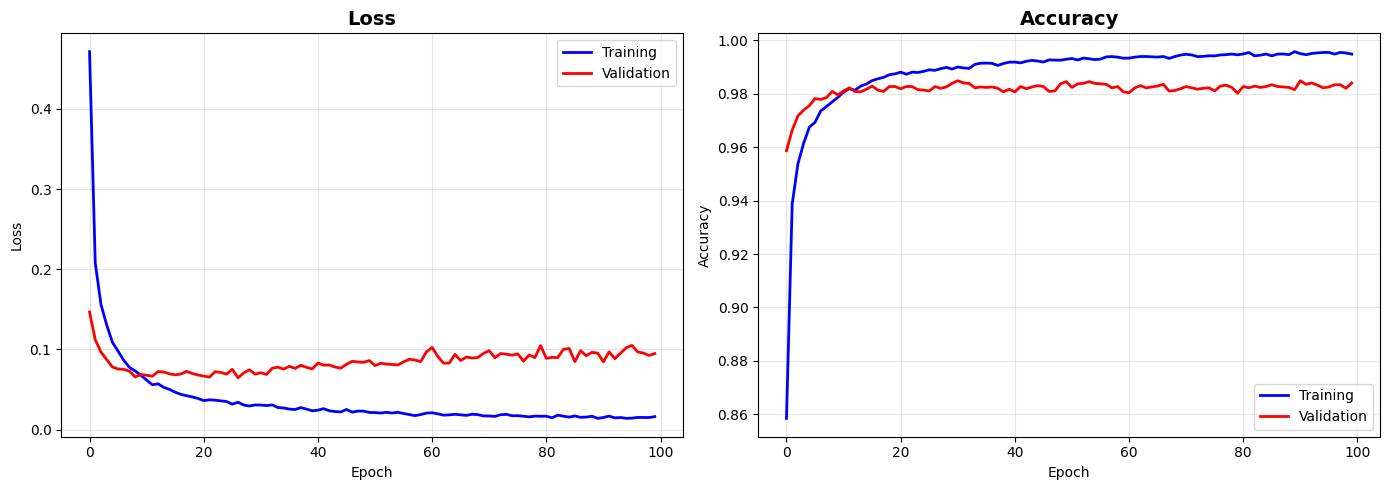

✅ The network learned to recognize digits!


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss
axes[0].plot(history.history['loss'], 'b-', label='Training', linewidth=2)
axes[0].plot(history.history['val_loss'], 'r-', label='Validation', linewidth=2)
axes[0].set_title('Loss', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy
axes[1].plot(history.history['accuracy'], 'b-', label='Training', linewidth=2)
axes[1].plot(history.history['val_accuracy'], 'r-', label='Validation', linewidth=2)
axes[1].set_title('Accuracy', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("✅ The network learned to recognize digits!")

---
## 🎯 Cell 10: Test on Specific Example

**Pick any test image (0-9999) and see the prediction!**

🎯 Testing specific examples...



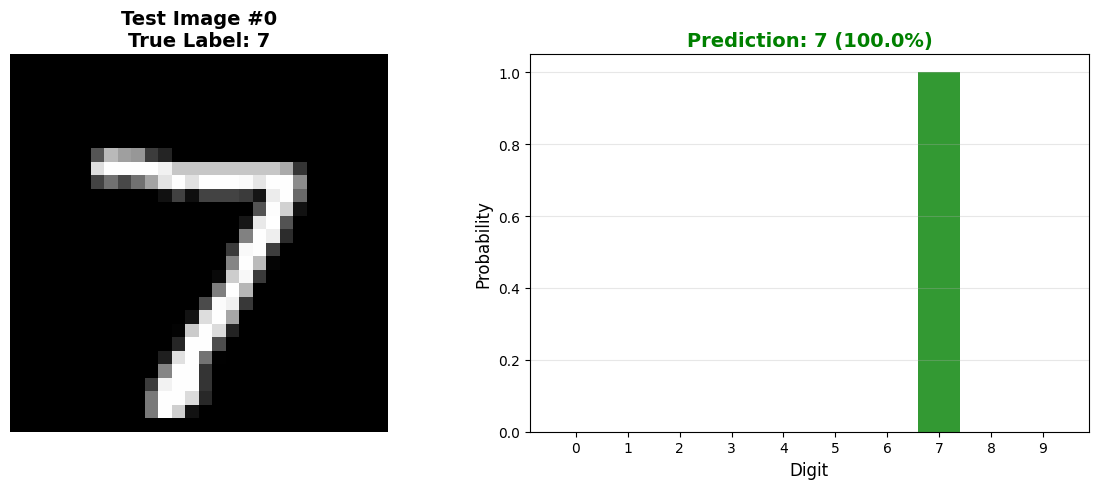


🎯 PREDICTION RESULTS
Test Image: #0
True Label: 7
Predicted: 7
Confidence: 100.00%

✅ CORRECT!

All probabilities:
  Digit 0:  0.00% 
  Digit 1:  0.00% 
  Digit 2:  0.00% 
  Digit 3:  0.00% 
  Digit 4:  0.00% 
  Digit 5:  0.00% 
  Digit 6:  0.00% 
  Digit 7: 100.00% ████████████████████████████████████████
  Digit 8:  0.00% 
  Digit 9:  0.00% 


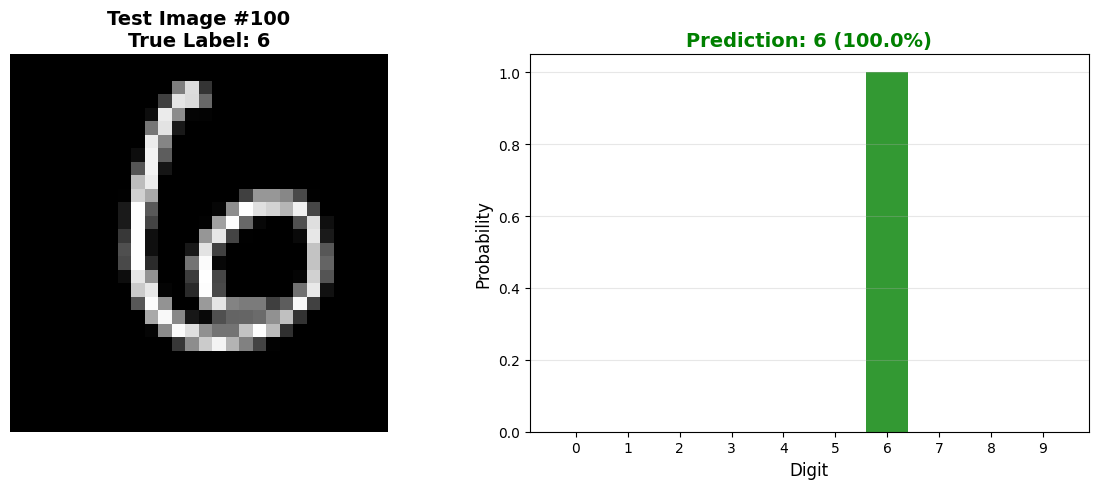


🎯 PREDICTION RESULTS
Test Image: #100
True Label: 6
Predicted: 6
Confidence: 100.00%

✅ CORRECT!

All probabilities:
  Digit 0:  0.00% 
  Digit 1:  0.00% 
  Digit 2:  0.00% 
  Digit 3:  0.00% 
  Digit 4:  0.00% 
  Digit 5:  0.00% 
  Digit 6: 100.00% ████████████████████████████████████████
  Digit 7:  0.00% 
  Digit 8:  0.00% 
  Digit 9:  0.00% 


In [10]:
def test_prediction(index):
    """
    Show prediction for a specific test image.
    """
    if index < 0 or index >= len(X_test):
        print(f"❌ Index must be between 0 and {len(X_test)-1}")
        return

    # Get image and true label
    image = X_test[index]
    true_label = y_test[index]

    # Make prediction
    image_input = X_test_flat[index].reshape(1, -1)
    prediction_proba = model.predict(image_input, verbose=0)[0]
    predicted_digit = np.argmax(prediction_proba)
    confidence = prediction_proba[predicted_digit]

    # Visualize
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Show image
    axes[0].imshow(image, cmap='gray')
    axes[0].set_title(f'Test Image #{index}\nTrue Label: {true_label}',
                     fontsize=14, fontweight='bold')
    axes[0].axis('off')

    # Show probabilities
    colors = ['green' if i == predicted_digit else 'lightgray' for i in range(10)]
    axes[1].bar(range(10), prediction_proba, color=colors, alpha=0.8)
    axes[1].set_title(f'Prediction: {predicted_digit} ({confidence*100:.1f}%)',
                     fontsize=14, fontweight='bold',
                     color='green' if predicted_digit == true_label else 'red')
    axes[1].set_xlabel('Digit', fontsize=12)
    axes[1].set_ylabel('Probability', fontsize=12)
    axes[1].set_xticks(range(10))
    axes[1].grid(True, alpha=0.3, axis='y')

    plt.tight_layout()
    plt.show()

    # Print results
    print(f"\n{'='*60}")
    print(f"🎯 PREDICTION RESULTS")
    print(f"{'='*60}")
    print(f"Test Image: #{index}")
    print(f"True Label: {true_label}")
    print(f"Predicted: {predicted_digit}")
    print(f"Confidence: {confidence*100:.2f}%")

    if predicted_digit == true_label:
        print(f"\n✅ CORRECT!")
    else:
        print(f"\n❌ INCORRECT! (Expected {true_label}, got {predicted_digit})")

    print(f"\nAll probabilities:")
    for i, prob in enumerate(prediction_proba):
        bar = '█' * int(prob * 40)
        print(f"  Digit {i}: {prob*100:5.2f}% {bar}")
    print(f"{'='*60}")

# Try it! Change the number to test different examples
print("🎯 Testing specific examples...\n")
test_prediction(0)
test_prediction(100)

---
## 🎲 Cell 11: Random Test Prediction

**Run this cell multiple times to see random predictions!**

🎲 Random test image: #5801



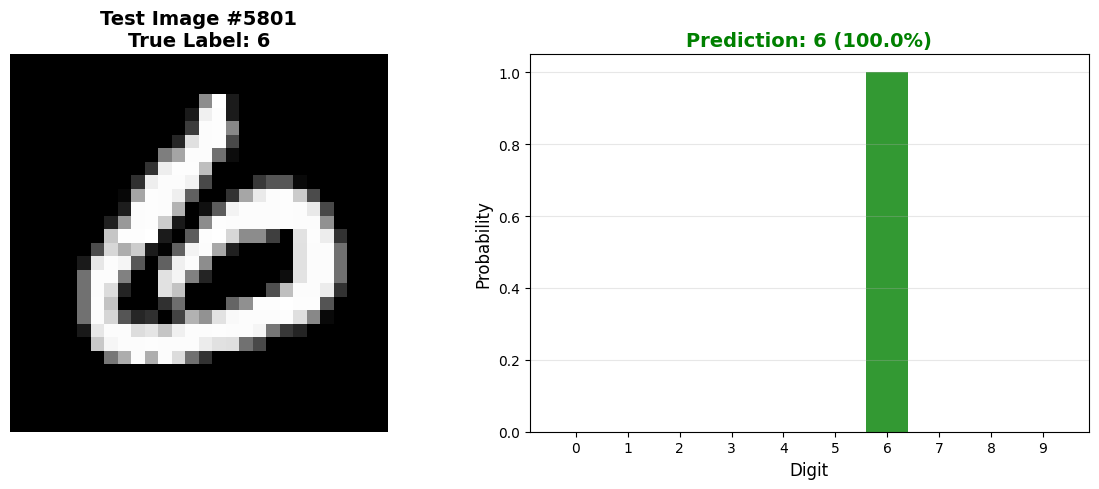


🎯 PREDICTION RESULTS
Test Image: #5801
True Label: 6
Predicted: 6
Confidence: 100.00%

✅ CORRECT!

All probabilities:
  Digit 0:  0.00% 
  Digit 1:  0.00% 
  Digit 2:  0.00% 
  Digit 3:  0.00% 
  Digit 4:  0.00% 
  Digit 5:  0.00% 
  Digit 6: 100.00% ███████████████████████████████████████
  Digit 7:  0.00% 
  Digit 8:  0.00% 
  Digit 9:  0.00% 

💡 Run this cell again to test another random image!


In [11]:
# Pick random test image
random_test_idx = np.random.randint(0, len(X_test))

print(f"🎲 Random test image: #{random_test_idx}\n")
test_prediction(random_test_idx)

print("\n💡 Run this cell again to test another random image!")

---
---
# 🎨 UPLOAD YOUR OWN DIGIT!
---
---

## 🖼️ Cell 12: Auto-Crop Function

This function automatically finds and prepares your digit, the same way the MNIST pictures were made:
the ink is separated from the paper, the digit is cropped, thin pen lines are thickened, and the digit is
scaled into a 20×20 box and centred in a 28×28 picture.

> **Why?** The network only knows MNIST-style pictures. The closer your photo looks to one, the better it guesses.

In [12]:
def auto_crop_and_preprocess(image_path, verbose=True):
    """
    Turn a photo of ONE handwritten digit (dark pen on light paper) into an MNIST-style input.
    Returns: original image, processed 28x28 image (0-1), network-ready input of shape (1, 784)

    It copies the recipe MNIST itself used: white digit on black, digit scaled to fit a 20x20 box
    (keeping its shape), then placed in a 28x28 frame so that its centre of mass sits in the middle.
    """
    say = print if verbose else (lambda *a, **k: None)
    img = cv2.imread(image_path)
    if img is None:
        say("❌ Could not read image!")
        return None, None, None
    original = img.copy()
    say(f"✓ Image loaded: {img.shape[1]}×{img.shape[0]} pixels")

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    # Otsu's method picks ONE threshold between paper and ink for the whole photo.
    # (A small adaptive-threshold window keeps only the EDGES of a thick marker stroke: hollow digits.)
    _, thresh = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    say("✓ Separated ink from paper (Otsu threshold)")

    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if len(contours) == 0:
        say("⚠️ No digit detected! Try a clearer image.")
        return None, None, None
    # Keep every blob at least 5% the size of the biggest: a 5, or a 7 with a bar, is often two strokes.
    areas = [cv2.contourArea(c) for c in contours]
    keep = [c for c, a in zip(contours, areas) if a >= 0.05 * max(areas)]
    x, y, w, h = cv2.boundingRect(np.vstack(keep))
    digit = thresh[y:y+h, x:x+w]
    say(f"✓ Digit found at x={x}, y={y}, size {w}×{h}")

    # MNIST strokes are about 1/8 of the digit's height; thicken thin pen lines to match.
    stroke = 2 * cv2.distanceTransform(digit, cv2.DIST_L2, 3).max()
    target = max(w, h) / 8
    if stroke < target:
        k = int(target - stroke) | 1
        digit = cv2.dilate(digit, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)))
        say(f"✓ Thickened thin strokes ({stroke:.0f} → about {target:.0f} pixels)")

    # Fit into a 20x20 box, keeping the aspect ratio
    scale = 20.0 / max(w, h)
    small = cv2.resize(digit, (max(1, round(w * scale)), max(1, round(h * scale))), interpolation=cv2.INTER_AREA)
    frame = np.zeros((28, 28), dtype=np.float32)
    top, left = (28 - small.shape[0]) // 2, (28 - small.shape[1]) // 2
    frame[top:top+small.shape[0], left:left+small.shape[1]] = small

    # Shift so the centre of mass is in the middle, as in MNIST
    total = frame.sum()
    if total > 0:
        rows, cols = np.indices(frame.shape)
        dy = int(round(13.5 - (rows * frame).sum() / total))
        dx = int(round(13.5 - (cols * frame).sum() / total))
        frame = cv2.warpAffine(frame, np.float32([[1, 0, dx], [0, 1, dy]]), (28, 28))
    say("✓ Scaled to 20×20 and centred in 28×28 (the MNIST recipe)")

    normalized = np.clip(frame / 255.0, 0, 1).astype('float32')
    network_input = normalized.reshape(1, -1)
    say("✓ Ready for classification!\n")
    return original, normalized, network_input

auto_crop_and_prepare = auto_crop_and_preprocess   # the name used in the cells below

# Where do the images come from?
#  • In Google Colab: an upload button appears (cancel it to use the demo images instead).
#  • In Jupyter / VS Code: put your own file names in MY_IMAGES below.
#  • With neither, the notebook draws demo "photos" so every cell still runs and shows the whole pipeline.
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

MY_IMAGES = []      # e.g. ["my_seven.jpg", "my_three.png"]  (used when not in Colab)


def make_demo_photo(digit, path=None, seed=0):
    """Draw a digit with a pen-like script font on slightly uneven paper, the way a phone photo looks."""
    rng = np.random.default_rng(seed + digit)
    H, W = 480, 400
    paper = np.linspace(225, 245, W)[None, :] * np.ones((H, 1))          # uneven lighting
    paper = paper + rng.normal(0, 4, (H, W))                             # sensor noise
    ink = np.zeros((H, W), np.uint8)
    cv2.putText(ink, str(digit), (95, 390), cv2.FONT_HERSHEY_SCRIPT_SIMPLEX, 11, 255, 26, cv2.LINE_AA)
    M = cv2.getRotationMatrix2D((W / 2, H / 2), rng.uniform(-8, 8), 1.0)  # a slightly tilted hand
    ink = cv2.warpAffine(ink, M, (W, H)).astype(float) / 255
    photo = paper * (1 - ink) + 35 * ink                                 # dark ink on light paper
    photo = np.clip(photo, 0, 255).astype(np.uint8)
    path = path or f"demo_digit_{digit}.png"
    cv2.imwrite(path, cv2.cvtColor(photo, cv2.COLOR_GRAY2BGR))
    return path


def get_images(demo_digits=(3,)):
    """Return a list of image file names to classify."""
    if IN_COLAB:
        uploaded = files.upload()
        if uploaded:
            return list(uploaded.keys())
    if MY_IMAGES:
        return list(MY_IMAGES)
    print(f"(No upload, so using demo photo(s) of {', '.join(map(str, demo_digits))}. "
          "Add your own file names to MY_IMAGES, or run this in Colab to upload.)\n")
    return [make_demo_photo(d) for d in demo_digits]

print("✅ Auto-crop function ready!")
print("Running in Colab:", IN_COLAB)

✅ Auto-crop function ready!
Running in Colab: False


---
## 🎯 Cell 13: UPLOAD YOUR DIGIT!

**Instructions:**
1. ✏️ Write a digit (0-9) on **WHITE paper** with **DARK pen**
2. 📸 Take a photo (JPG/PNG)
3. ⬆️ Upload below
4. 🎉 Watch AI auto-detect, crop & classify!

**The AI will automatically:**
- Find your digit in the image
- Crop it perfectly
- Resize to 28×28
- Tell you which digit (0-9)!

📤 UPLOAD YOUR HANDWRITTEN DIGIT
✏️  Write digit (0-9) on WHITE paper with DARK pen
📸 Take a clear photo
⬆️  Upload below!

(No upload, so using demo photo(s) of 3. Add your own file names to MY_IMAGES, or run this in Colab to upload.)


Processing: demo_digit_3.png

✓ Image loaded: 400×480 pixels
✓ Separated ink from paper (Otsu threshold)
✓ Digit found at x=112, y=144, size 182×261
✓ Scaled to 20×20 and centred in 28×28 (the MNIST recipe)
✓ Ready for classification!



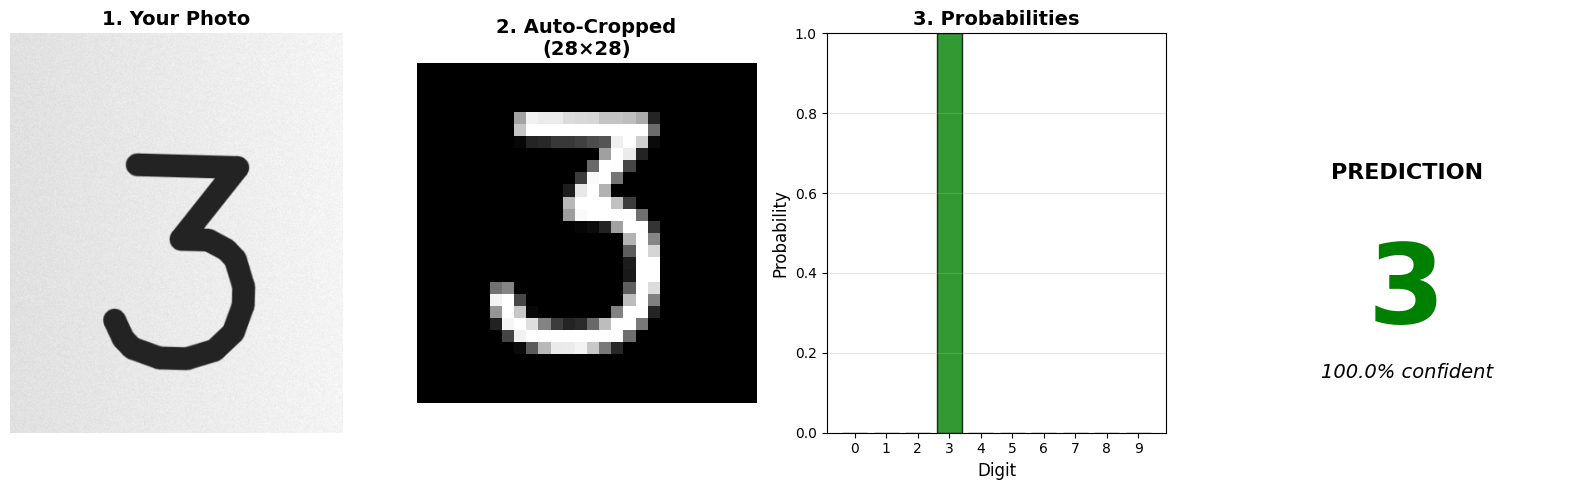


🎯 CLASSIFICATION RESULTS
Predicted Digit: 3
Confidence: 100.00%

Probability breakdown:
  Digit 0:  0.00% 
  Digit 1:  0.00% 
  Digit 2:  0.00% 
  Digit 3: 100.00% ████████████████████████████████████████ ⭐
  Digit 4:  0.00% 
  Digit 5:  0.00% 
  Digit 6:  0.00% 
  Digit 7:  0.00% 
  Digit 8:  0.00% 
  Digit 9:  0.00% 

✅ Done! The network thinks your digit is: 3


In [13]:
print("📤 UPLOAD YOUR HANDWRITTEN DIGIT")
print("="*60)
print("✏️  Write digit (0-9) on WHITE paper with DARK pen")
print("📸 Take a clear photo")
print("⬆️  Upload below!")
print("="*60)
print()

# Upload file (or use a demo photo outside Colab)
for filename in get_images(demo_digits=(3,)):
    print(f"\n{'='*60}")
    print(f"Processing: {filename}")
    print(f"{'='*60}\n")

    # Auto-crop and prepare
    original, processed, network_input = auto_crop_and_prepare(filename)

    if processed is None:
        print("\n⚠️ Could not process image. Try:")
        print("  • Darker pen/marker")
        print("  • Better lighting")
        print("  • Clearer image")
        continue

    # Make prediction
    prediction_proba = model.predict(network_input, verbose=0)[0]
    predicted_digit = np.argmax(prediction_proba)
    confidence = prediction_proba[predicted_digit]

    # Create visualization
    fig = plt.figure(figsize=(16, 5))

    # 1. Original image
    ax1 = plt.subplot(1, 4, 1)
    ax1.imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
    ax1.set_title('1. Your Photo', fontsize=14, fontweight='bold')
    ax1.axis('off')

    # 2. Processed 28×28
    ax2 = plt.subplot(1, 4, 2)
    ax2.imshow(processed, cmap='gray')
    ax2.set_title('2. Auto-Cropped\n(28×28)', fontsize=14, fontweight='bold')
    ax2.axis('off')

    # 3. Probabilities
    ax3 = plt.subplot(1, 4, 3)
    colors = ['green' if i == predicted_digit else 'lightgray' for i in range(10)]
    ax3.bar(range(10), prediction_proba, color=colors, alpha=0.8, edgecolor='black')
    ax3.set_title('3. Probabilities', fontsize=14, fontweight='bold')
    ax3.set_xlabel('Digit', fontsize=12)
    ax3.set_ylabel('Probability', fontsize=12)
    ax3.set_xticks(range(10))
    ax3.set_ylim([0, 1])
    ax3.grid(True, alpha=0.3, axis='y')

    # 4. Final prediction
    ax4 = plt.subplot(1, 4, 4)
    ax4.text(0.5, 0.65, 'PREDICTION', ha='center', va='center',
            fontsize=16, fontweight='bold')
    ax4.text(0.5, 0.35, f'{predicted_digit}', ha='center', va='center',
            fontsize=80, fontweight='bold', color='green')
    ax4.text(0.5, 0.15, f'{confidence*100:.1f}% confident', ha='center', va='center',
            fontsize=14, style='italic')
    ax4.set_xlim(0, 1)
    ax4.set_ylim(0, 1)
    ax4.axis('off')

    plt.tight_layout()
    plt.show()

    # Print detailed results
    print(f"\n{'='*60}")
    print(f"🎯 CLASSIFICATION RESULTS")
    print(f"{'='*60}")
    print(f"Predicted Digit: {predicted_digit}")
    print(f"Confidence: {confidence*100:.2f}%")
    print(f"\nProbability breakdown:")
    for i, prob in enumerate(prediction_proba):
        bar = '█' * int(prob * 40)
        star = ' ⭐' if i == predicted_digit else ''
        print(f"  Digit {i}: {prob*100:5.2f}% {bar}{star}")
    print(f"{'='*60}")

    print(f"\n✅ Done! The network thinks your digit is: {predicted_digit}")

---
## 💡 Cell 14: Tips for Best Results

In [14]:
print("💡 TIPS FOR BETTER RECOGNITION")
print("="*60)

print("\n✅ DO THIS:")
print("  • Use DARK pen/marker on WHITE paper")
print("  • Write LARGE and BOLD")
print("  • Write like the MNIST examples (simple style)")
print("  • Good lighting (natural daylight is best)")
print("  • Hold camera straight (not at angle)")
print("  • Fill most of the image with your digit")

print("\n❌ AVOID THIS:")
print("  • Light pencils or faint pens")
print("  • Tiny digits")
print("  • Fancy or decorative writing")
print("  • Blurry photos")
print("  • Colored or patterned backgrounds")
print("  • Multiple digits in one photo")

print("\n🎯 HOW AUTO-CROP WORKS:")
print("  1. Converts to grayscale")
print("  2. Separates ink from paper (Otsu threshold)")
print("  3. Finds all the digit's strokes")
print("  4. Crops around them")
print("  5. Thickens thin pen lines")
print("  6. Fits the digit in a 20×20 box")
print("  7. Centres it in 28×28 (like MNIST)")
print("  8. Feeds to network")
print("  9. Returns digit & confidence!")

print("\n📊 COMMON CONFUSIONS:")
print("  The AI sometimes confuses:")
print("  • 1 and 7 (if written similarly)")
print("  • 3 and 8 (if poorly written)")
print("  • 4 and 9 (handwriting variations)")
print("  • 5 and 6 (if curves are unclear)")
print("  Write clearly to avoid confusion!")

print("="*60)

💡 TIPS FOR BETTER RECOGNITION

✅ DO THIS:
  • Use DARK pen/marker on WHITE paper
  • Write LARGE and BOLD
  • Write like the MNIST examples (simple style)
  • Good lighting (natural daylight is best)
  • Hold camera straight (not at angle)
  • Fill most of the image with your digit

❌ AVOID THIS:
  • Light pencils or faint pens
  • Tiny digits
  • Fancy or decorative writing
  • Blurry photos
  • Colored or patterned backgrounds
  • Multiple digits in one photo

🎯 HOW AUTO-CROP WORKS:
  1. Converts to grayscale
  2. Separates ink from paper (Otsu threshold)
  3. Finds all the digit's strokes
  4. Crops around them
  5. Thickens thin pen lines
  6. Fits the digit in a 20×20 box
  7. Centres it in 28×28 (like MNIST)
  8. Feeds to network
  9. Returns digit & confidence!

📊 COMMON CONFUSIONS:
  The AI sometimes confuses:
  • 1 and 7 (if written similarly)
  • 3 and 8 (if poorly written)
  • 4 and 9 (handwriting variations)
  • 5 and 6 (if curves are unclear)
  Write clearly to avoid confu

---
## 🎓 Cell 15: Summary

In [15]:
# Calculate test accuracy
test_predictions = model.predict(X_test_flat, verbose=0)
test_accuracy = np.mean(np.argmax(test_predictions, axis=1) == y_test)

print(f"\n{'='*60}")
print("🎓 PROJECT COMPLETE!")
print(f"{'='*60}")

print("\n🧠 WHAT WE DID:")
print("  • Explored MNIST dataset interactively")
print("  • Built neural network (784→128→64→10)")
print("  • Trained to recognize digits 0-9")
print("  • Created auto-crop preprocessing")
print("  • Classified YOUR handwritten digit!")

print("\n📊 PERFORMANCE:")
print(f"  • Training accuracy: {history.history['accuracy'][-1]*100:.2f}%")
print(f"  • Test accuracy: {test_accuracy*100:.2f}%")
print(f"  • Trained on: 54,000 images (+6,000 for validation)")
print(f"  • Tested on: 10,000 images")

print("\n🎯 KEY FEATURES:")
print("  ✓ Interactive MNIST explorer")
print("  ✓ Pick any image to test")
print("  ✓ Random image testing")
print("  ✓ Auto-detect & crop uploads")
print("  ✓ Real-time classification")
print("  ✓ Confidence scores & probabilities")

print("\n🚀 NEXT STEPS:")
print("  • Try Convolutional Neural Networks (CNNs)")
print("  • Add data augmentation")
print("  • Build a web app")
print("  • Extend to letters (A-Z)")
print("  • Try other datasets")

print(f"\n{'='*60}")
print("✨ Great job! You built a working digit recognizer! ✨")
print(f"{'='*60}")


🎓 PROJECT COMPLETE!

🧠 WHAT WE DID:
  • Explored MNIST dataset interactively
  • Built neural network (784→128→64→10)
  • Trained to recognize digits 0-9
  • Created auto-crop preprocessing
  • Classified YOUR handwritten digit!

📊 PERFORMANCE:
  • Training accuracy: 99.48%
  • Test accuracy: 98.13%
  • Trained on: 54,000 images (+6,000 for validation)
  • Tested on: 10,000 images

🎯 KEY FEATURES:
  ✓ Interactive MNIST explorer
  ✓ Pick any image to test
  ✓ Random image testing
  ✓ Auto-detect & crop uploads
  ✓ Real-time classification
  ✓ Confidence scores & probabilities

🚀 NEXT STEPS:
  • Try Convolutional Neural Networks (CNNs)
  • Add data augmentation
  • Build a web app
  • Extend to letters (A-Z)
  • Try other datasets

✨ Great job! You built a working digit recognizer! ✨
